# Diabetes ML: imbalance-aware status classification

Investigate how class weighting, focal loss, boosted trees and decision tuning affect three-class diabetes status classification from BRFSS health indicators. This notebook presents data exploration and the evaluated model comparison. It reads saved artifacts; training is a separate, explicit command. See `METHODOLOGY.md` for the experimental protocol.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image, Markdown
from diabetes_ml.common import ROOT, FEATURES, TARGET
raw = pd.read_csv(ROOT / 'data/raw/diabetes_012_health_indicators_BRFSS2015.csv')
print('Project:', ROOT)
print('Shape:', raw.shape)
display(raw.head())

Project: /Users/newosaka/Private Project/Diabetes ML
Shape: (253680, 22)


,Diabetes_012,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,...,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
0,0.0,1.0,1.0,1.0,40.0,1.0,0.0,0.0,0.0,0.0,...,1.0,0.0,5.0,18.0,15.0,1.0,0.0,9.0,4.0,3.0
1,0.0,0.0,0.0,0.0,25.0,1.0,0.0,0.0,1.0,0.0,...,0.0,1.0,3.0,0.0,0.0,0.0,0.0,7.0,6.0,1.0
2,0.0,1.0,1.0,1.0,28.0,0.0,0.0,0.0,0.0,1.0,...,1.0,1.0,5.0,30.0,30.0,1.0,0.0,9.0,4.0,8.0
3,0.0,1.0,0.0,1.0,27.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,0.0,0.0,0.0,0.0,11.0,3.0,6.0
4,0.0,1.0,1.0,1.0,24.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,3.0,0.0,0.0,0.0,11.0,5.0,4.0


## Schema and quality
Zero is a valid survey response, not a missing-value code. Ordinal fields, including Age, are categories rather than literal years.

In [2]:
audit = json.loads((ROOT / 'results/data_audit.json').read_text())
display(pd.Series({k: audit[k] for k in ['rows','feature_count','missing_cells','duplicate_full_rows_after_first','duplicate_feature_profiles_after_first','test_profiles_seen_in_training']}))
display(raw.describe().T)

rows                                      253680
feature_count                                 21
missing_cells                                  0
duplicate_full_rows_after_first            23899
duplicate_feature_profiles_after_first     25772
test_profiles_seen_in_training              3480
dtype: int64

,count,mean,std,min,25%,50%,75%,max
Diabetes_012,253680.0,0.296921,0.698160,0.0,0.0,0.0,0.0,2.0
HighBP,253680.0,0.429001,0.494934,0.0,0.0,0.0,1.0,1.0
HighChol,253680.0,0.424121,0.494210,0.0,0.0,0.0,1.0,1.0
CholCheck,253680.0,0.962670,0.189571,0.0,1.0,1.0,1.0,1.0
BMI,253680.0,28.382364,6.608694,12.0,24.0,27.0,31.0,98.0
Smoker,253680.0,0.443169,0.496761,0.0,0.0,0.0,1.0,1.0
Stroke,253680.0,0.040571,0.197294,0.0,0.0,0.0,0.0,1.0
HeartDiseaseorAttack,253680.0,0.094186,0.292087,0.0,0.0,0.0,0.0,1.0
PhysActivity,253680.0,0.756544,0.429169,0.0,1.0,1.0,1.0,1.0
Fruits,253680.0,0.634256,0.481639,0.0,0.0,1.0,1.0,1.0


## Class imbalance and feature distributions
The prediabetes class contains only about 1.8% of responses.

,count
class,
0.0,213703
1.0,4631
2.0,35346


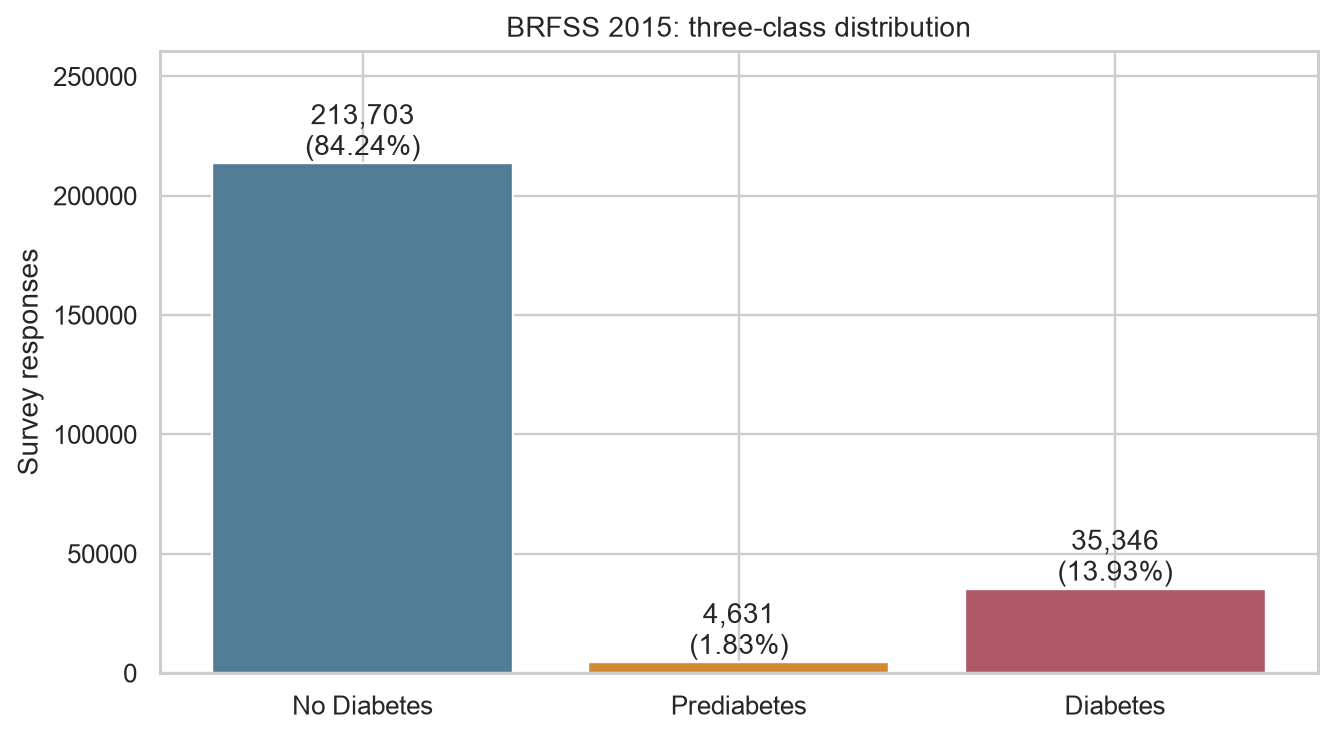

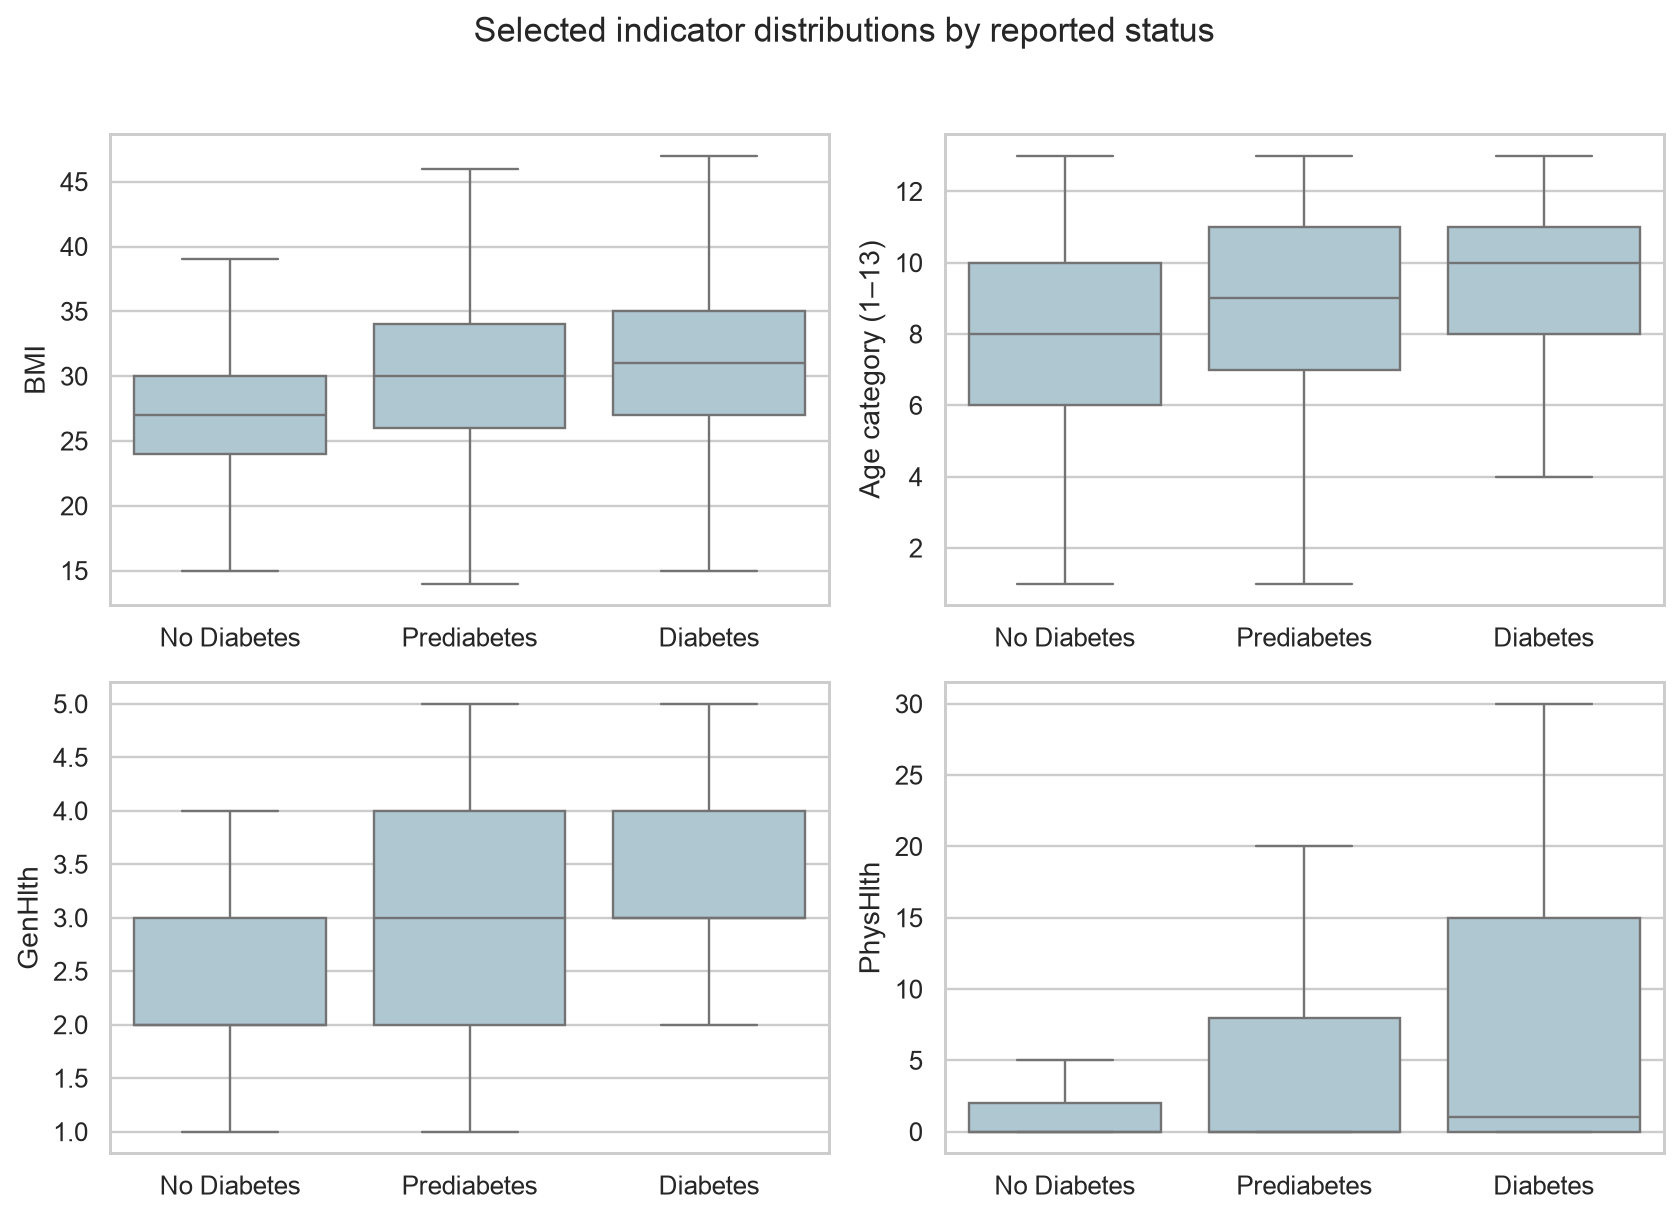

In [3]:
display(raw[TARGET].value_counts().sort_index().rename_axis('class').to_frame('count'))
display(Image(filename=str(ROOT / 'results/figures/class_distribution.png')))
display(Image(filename=str(ROOT / 'results/figures/indicator_distributions.png')))

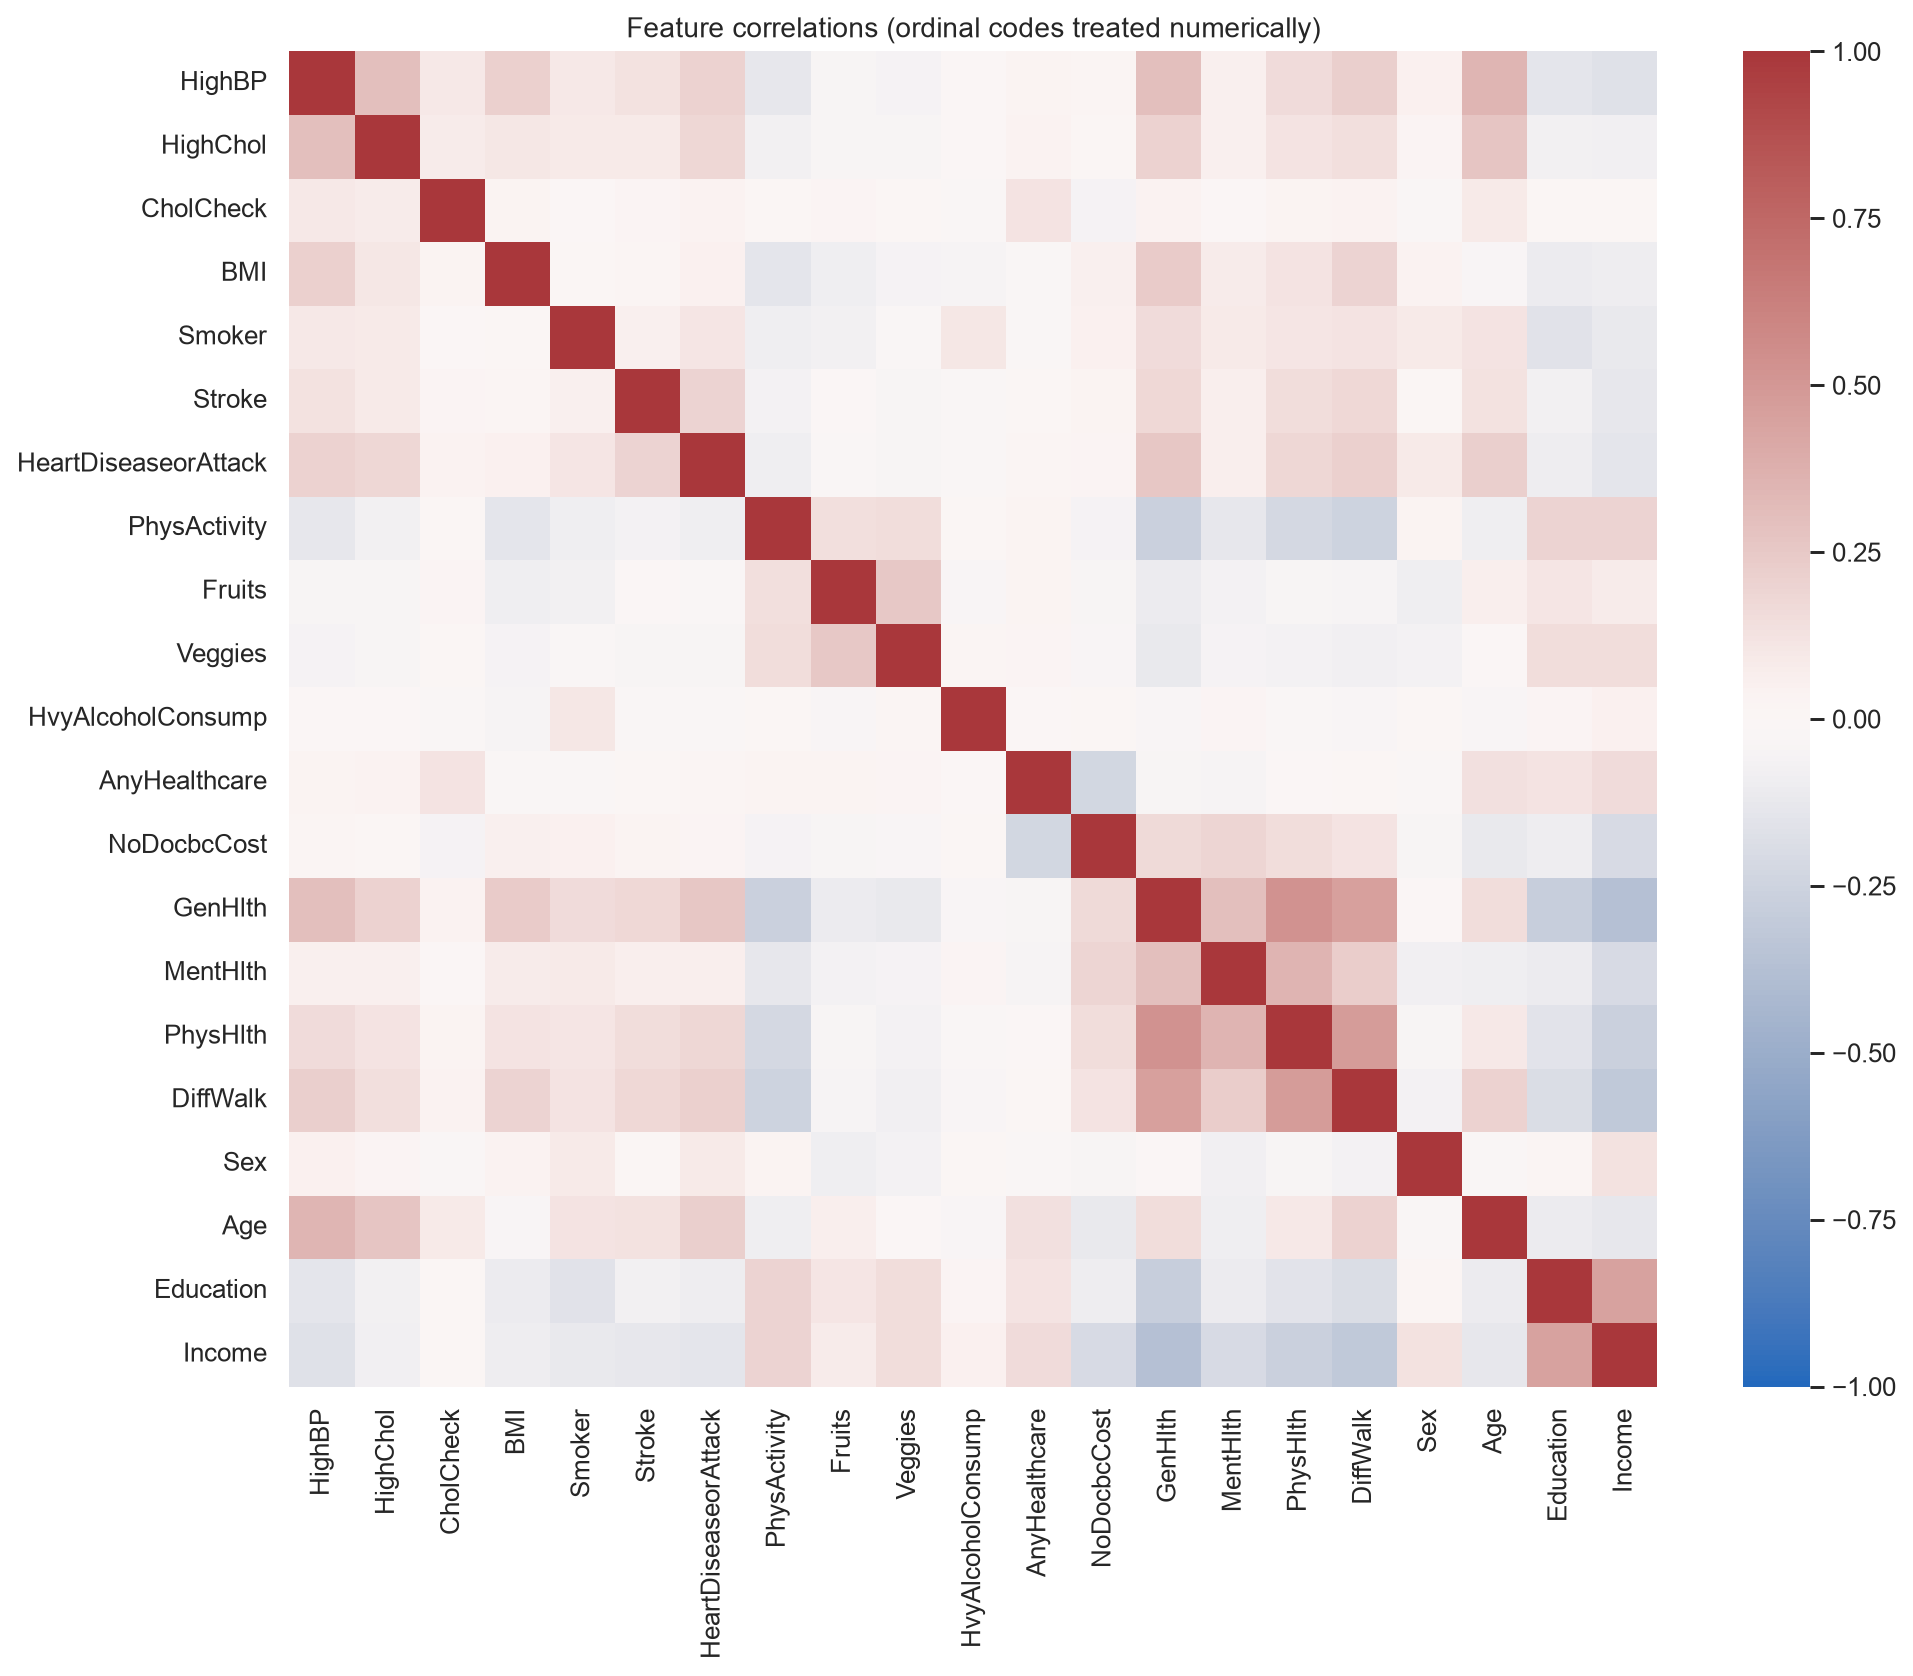

In [4]:
display(Image(filename=str(ROOT / 'results/figures/feature_correlations.png')))

## Fixed partitions and training-only preprocessing
80% training, 5% tuning, 5% selection, 10% test. Persisted row IDs are never predictors. Selection chooses the final model before test inference.

In [5]:
display(pd.read_csv(ROOT / 'results/split_counts.csv'))
manifest = json.loads((ROOT / 'models/selection_manifest.json').read_text())
display(manifest['champion'])
print('Frozen before test evaluation:', manifest['frozen_at_utc'])

,split,class,count,total
0,train,0,170962,202944
1,train,1,3705,202944
2,train,2,28277,202944
3,tuning,0,10685,12684
4,tuning,1,232,12684
5,tuning,2,1767,12684
6,selection,0,10685,12684
7,selection,1,231,12684
8,selection,2,1768,12684
9,test,0,21371,25368


{'label': 'champion',
 'model': 'mlp_sqrt_weighted',
 'decision': 'tuned',
 'offsets': [0.0, 1.0, 0.0],
 'selection_macro_f1': 0.4727951059448137}

Frozen before test evaluation: 2026-10-28T14:53:30.067498+00:00


## Candidate comparison on selection data
Focal loss, class weighting, boosted trees, decision offsets and soft voting are compared using macro F1. Selection results are model-selection estimates, not final generalization claims.

In [6]:
experiments = pd.read_csv(ROOT / 'results/experiment_results.csv')
selection = experiments[experiments.split.eq('selection')].sort_values(['macro_f1','balanced_accuracy'], ascending=False, kind='stable')
display(selection[['model','decision','accuracy','balanced_accuracy','macro_f1','prediabetes_recall']].reset_index(drop=True))

,model,decision,accuracy,balanced_accuracy,macro_f1,prediabetes_recall
0,mlp_sqrt_weighted,tuned,0.806291,0.486851,0.472795,0.077922
1,catboost_depth6_weight0.5,tuned,0.807159,0.481683,0.470302,0.082251
2,ensemble_trees,tuned,0.805740,0.481925,0.468960,0.064935
3,hist_gradient_weight0,tuned,0.790918,0.488924,0.467472,0.103896
4,catboost_depth7_weight0.5,tuned,0.781220,0.497670,0.467387,0.108225
5,ensemble_trees_mlp,tuned,0.783507,0.494007,0.466933,0.112554
6,catboost_depth5_weight0,tuned,0.804715,0.480742,0.466809,0.056277
7,hist_gradient_weight0.5,tuned,0.803217,0.476513,0.465320,0.073593
8,mlp_baseline,tuned,0.788158,0.485646,0.463464,0.086580
9,catboost_depth6_weight1,tuned,0.774204,0.492078,0.460366,0.090909


## Training curves
The baseline uses ordinary cross-entropy. Other train objectives may be weighted or focal, while validation CE is always ordinary cross-entropy; their loss scales differ.

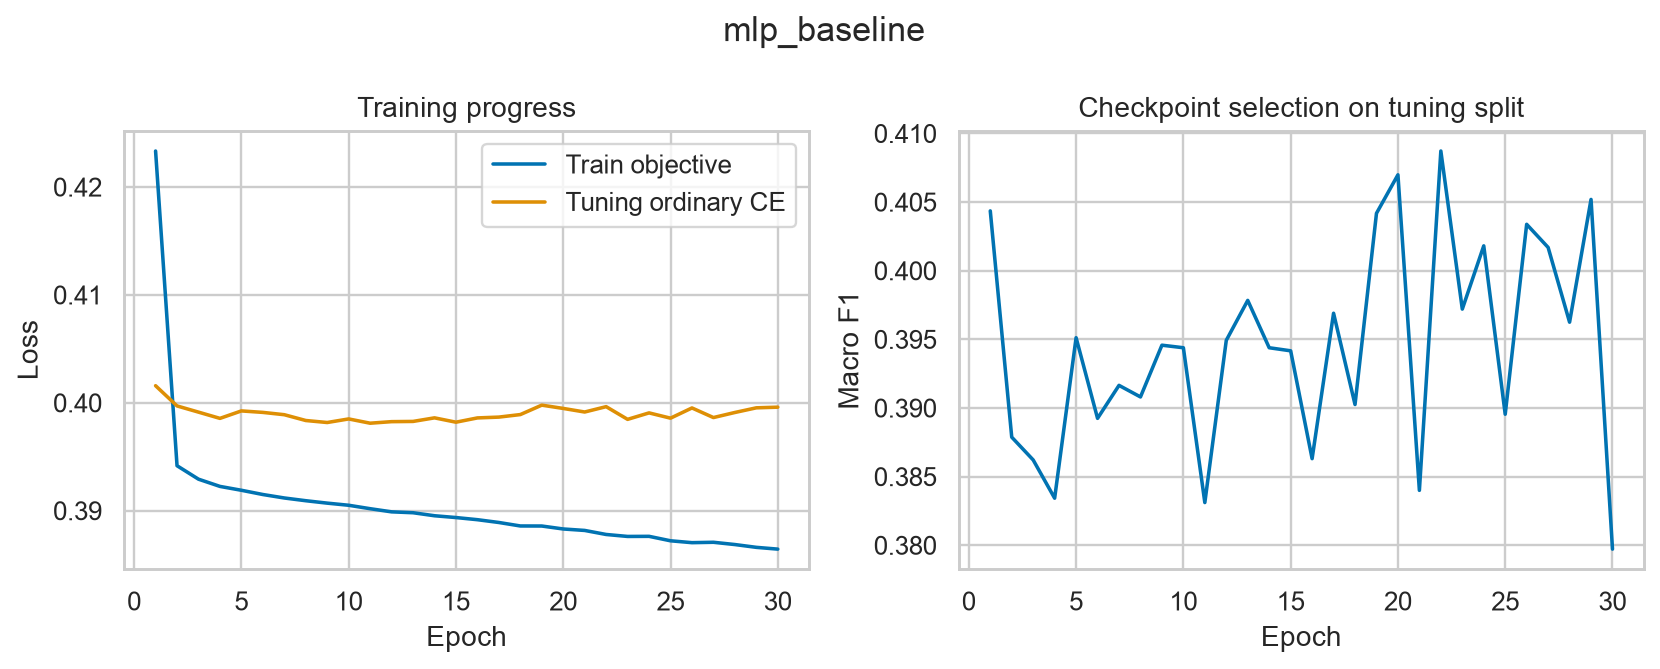

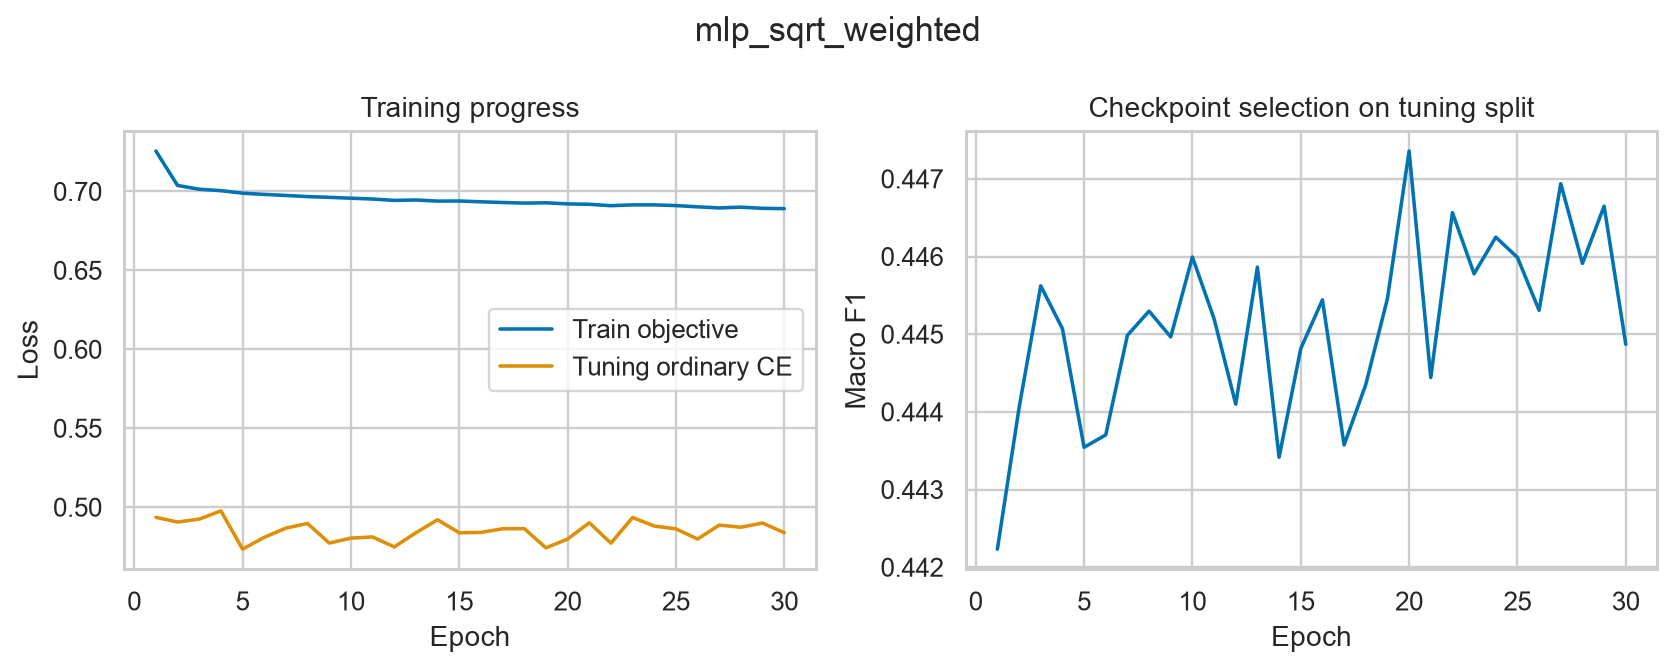

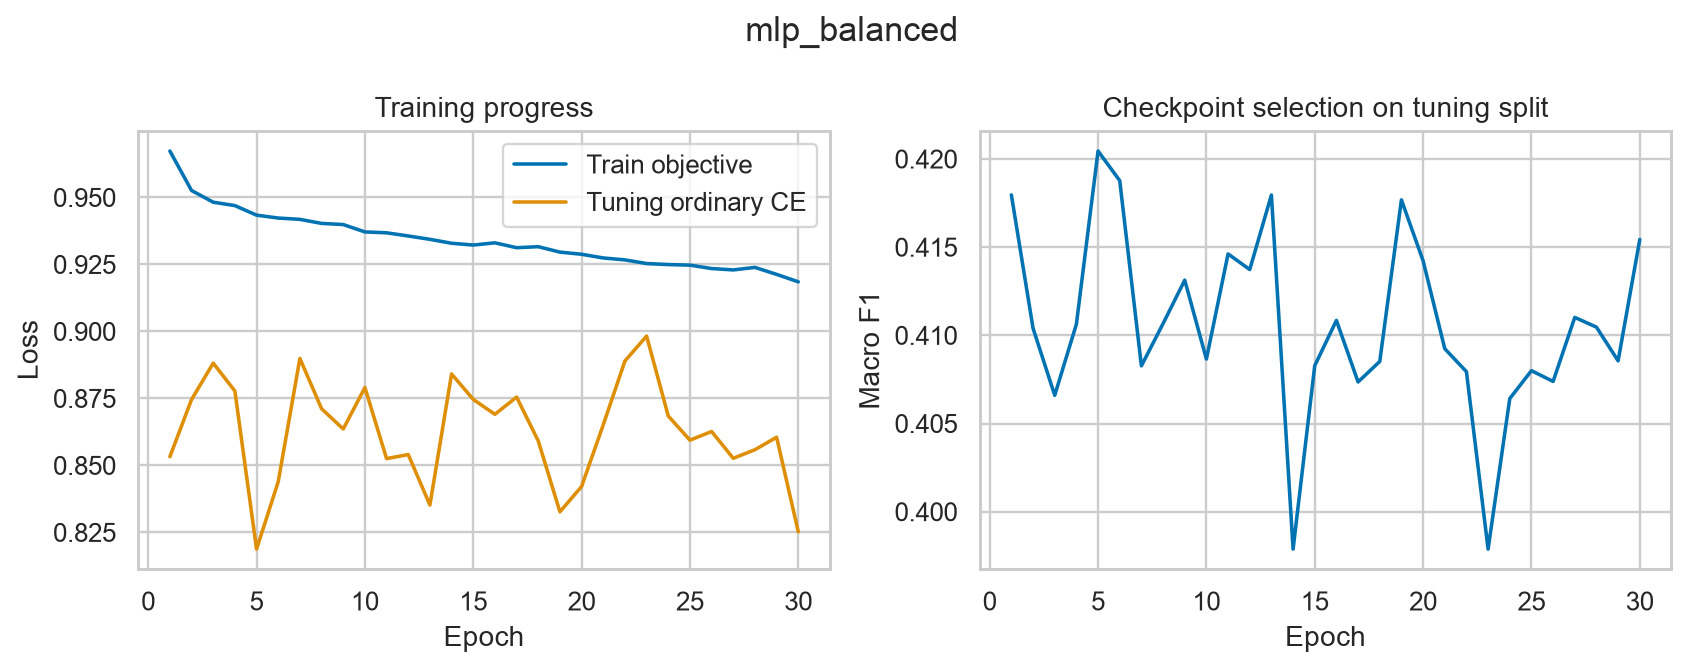

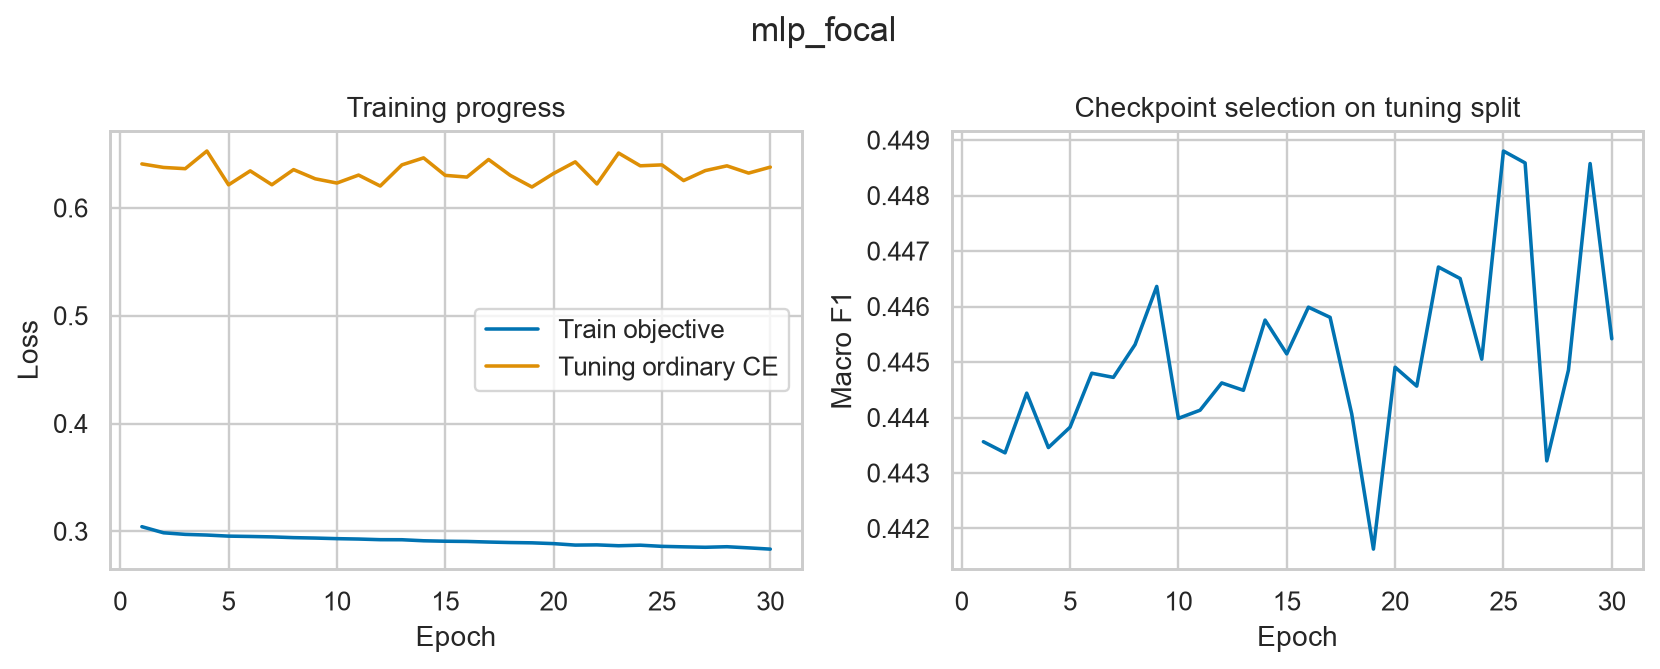

In [7]:
for name in ['mlp_baseline','mlp_sqrt_weighted','mlp_balanced','mlp_focal']:
    display(Image(filename=str(ROOT / f'results/figures/{name}_loss.png')))

## Logistic coefficient associations
Inputs are standardized using training statistics. Coefficients describe model associations, not causes.

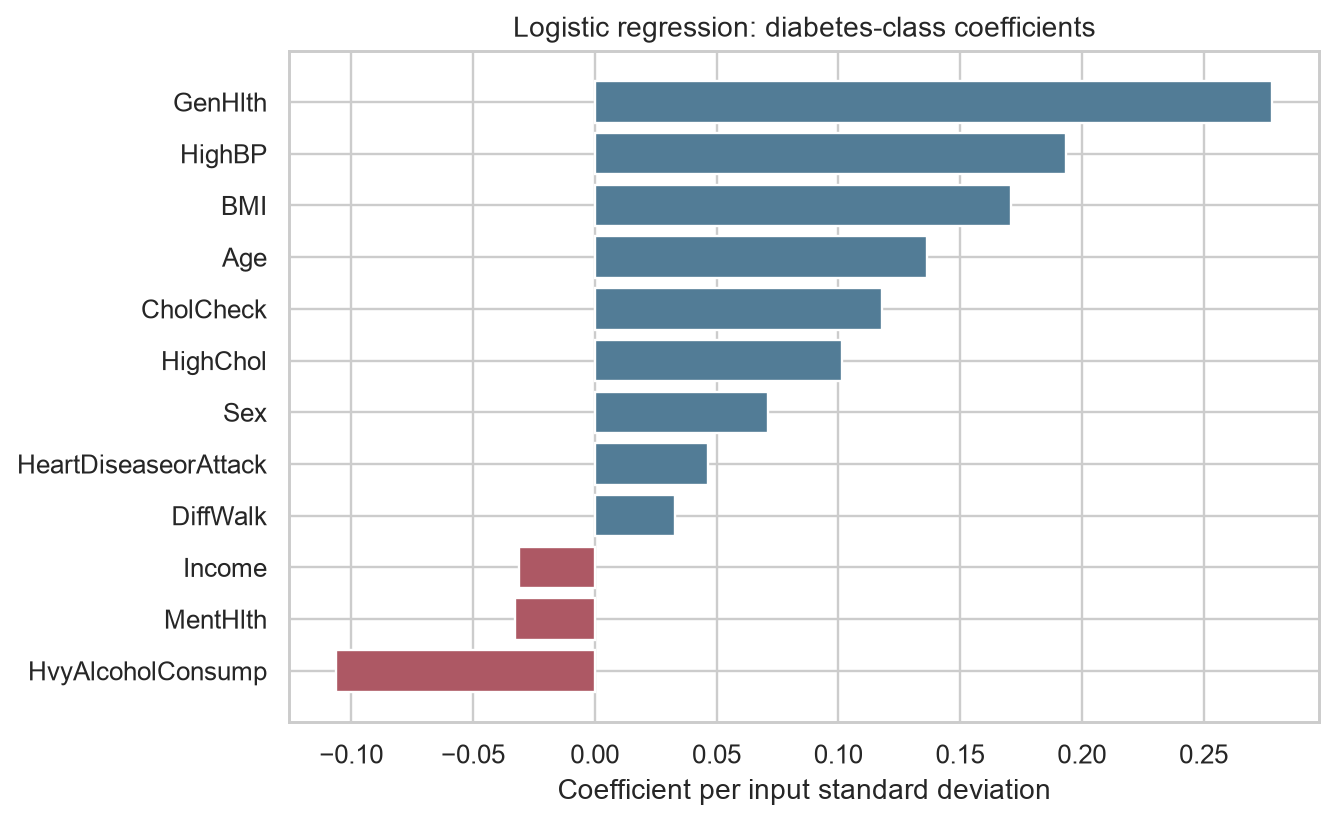

In [8]:
display(Image(filename=str(ROOT / 'results/figures/logistic_coefficients.png')))

## Frozen held-out test comparison
The validation-selected champion is retained even if another frozen model has a slightly higher test score. Best improved MLP and champion are the same fitted model.

,model,underlying_model,decision,accuracy,balanced_accuracy,macro_f1,prediabetes_recall,prediabetes_precision,diabetes_recall
0,dummy,dummy,argmax,0.842439,0.333333,0.304828,0.000000,0.000000,0.000000
1,logistic_baseline,logistic_baseline,argmax,0.847524,0.383761,0.392990,0.000000,0.000000,0.174024
2,mlp_baseline,mlp_baseline,argmax,0.848155,0.400306,0.412797,0.000000,0.000000,0.232598
3,best_weighted_logistic,logistic_weighted_C1,tuned,0.777870,0.491224,0.455590,0.034557,0.041775,0.618846
4,best_improved_mlp,mlp_sqrt_weighted,tuned,0.805227,0.480818,0.467490,0.062635,0.044207,0.509621
5,best_boosted_tree,catboost_depth6_weight0.5,tuned,0.810233,0.480586,0.469920,0.066955,0.047913,0.496604
6,champion,mlp_sqrt_weighted,tuned,0.805227,0.480818,0.467490,0.062635,0.044207,0.509621
7,champion_argmax_ablation,mlp_sqrt_weighted,argmax,0.819694,0.473910,0.455237,0.000000,0.000000,0.537634


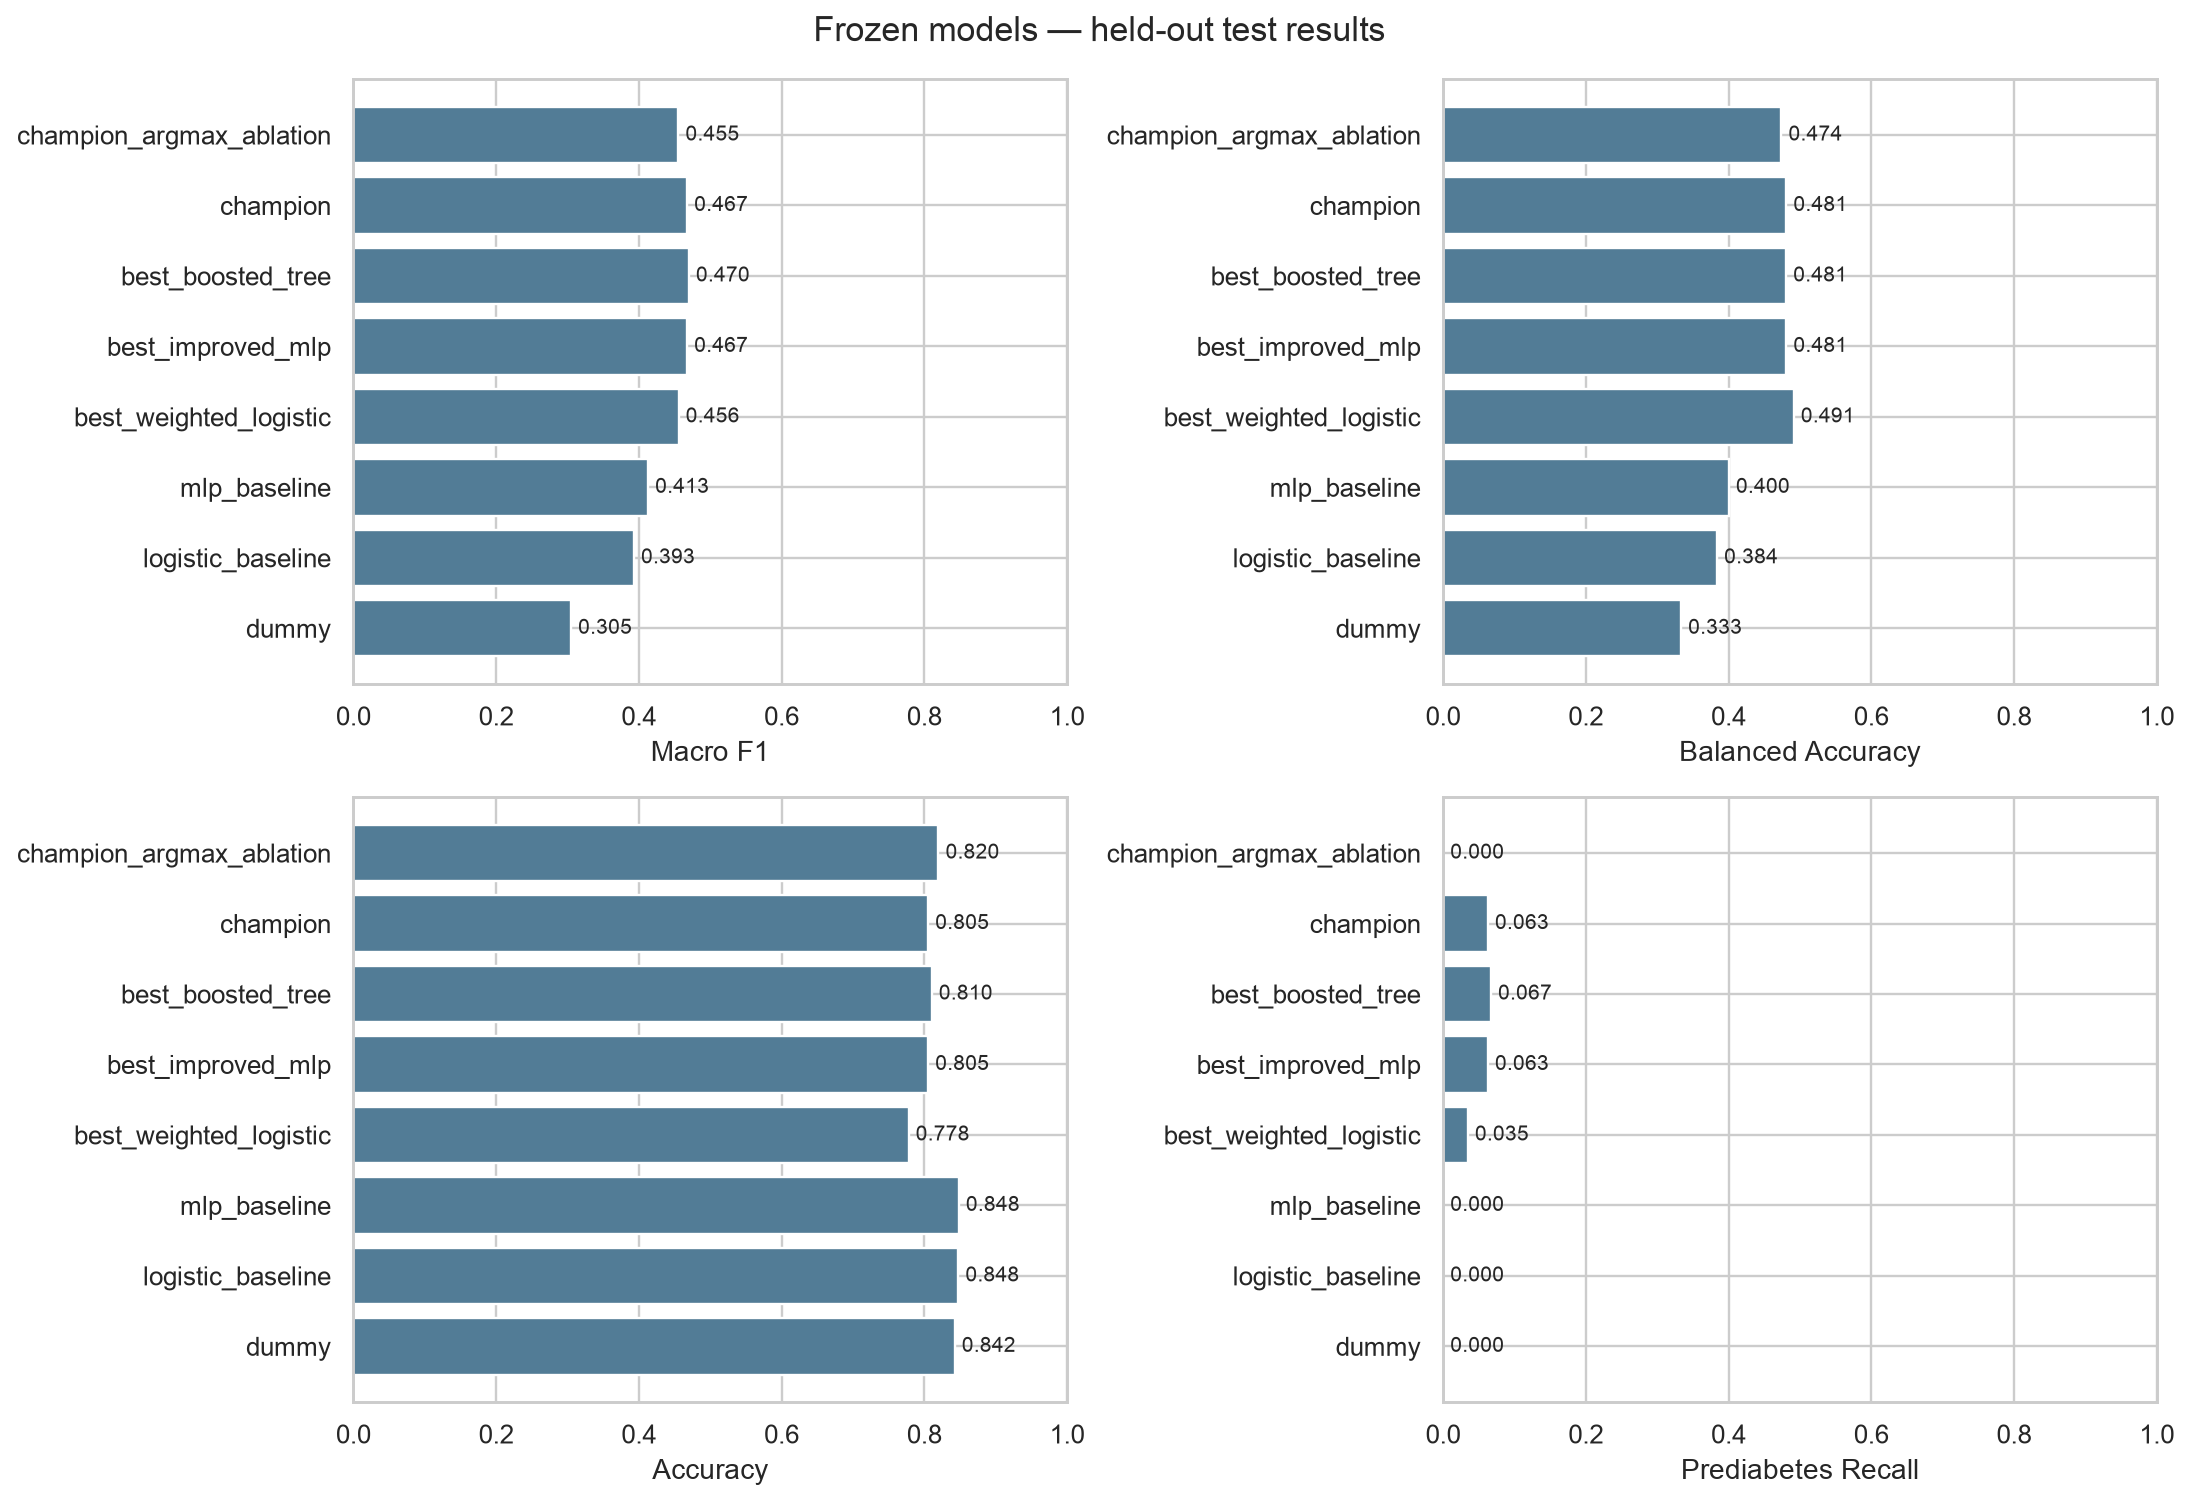

In [9]:
test_results = pd.read_csv(ROOT / 'results/test_results.csv')
display(test_results)
display(Image(filename=str(ROOT / 'results/figures/test_comparison.png')))

,class,precision,recall,specificity,f1,support,average_precision
0,No Diabetes,0.910279,0.870198,0.541406,0.889787,21371,0.960555
1,Prediabetes,0.044207,0.062635,0.974824,0.051832,463,0.033918
2,Diabetes,0.420598,0.509621,0.886370,0.460850,3534,0.437551


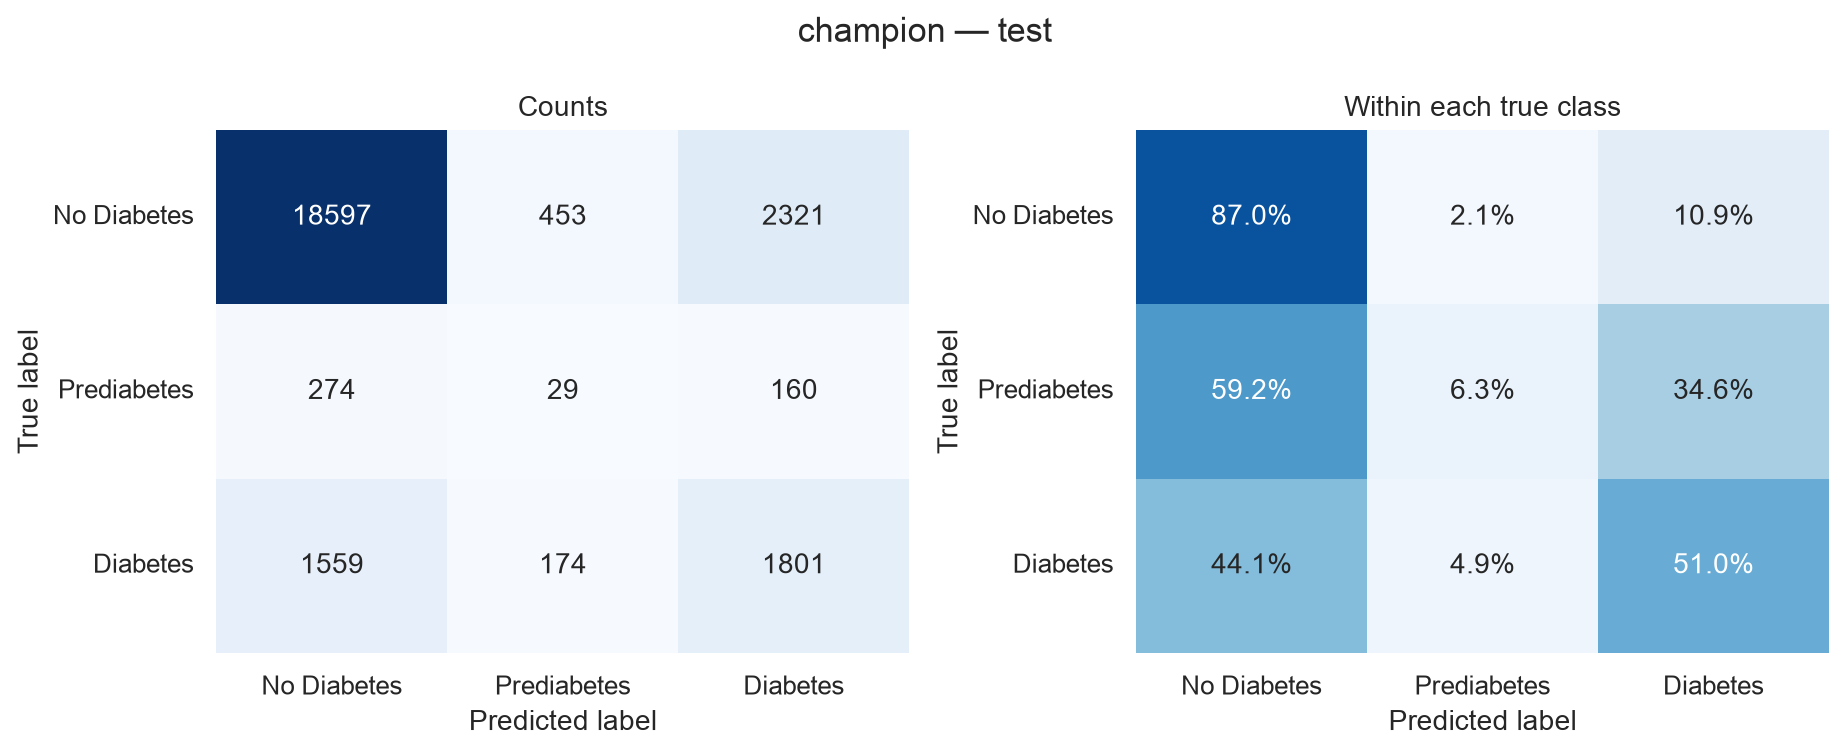

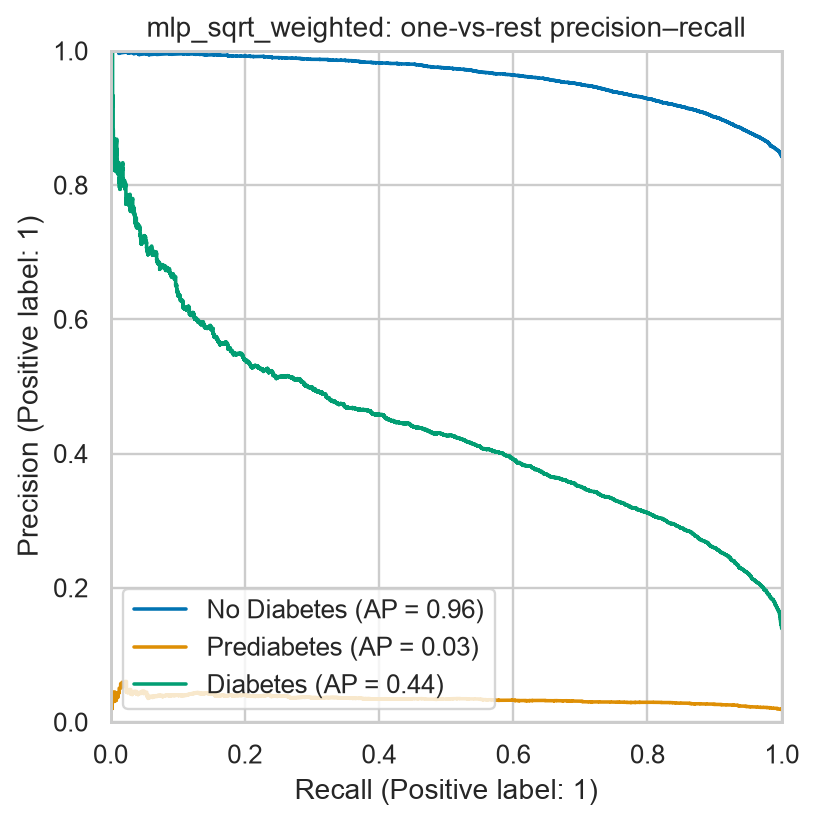

In [10]:
display(pd.read_csv(ROOT / 'results/champion_test_classes.csv'))
display(Image(filename=str(ROOT / 'results/figures/champion_test_confusion.png')))
display(Image(filename=str(ROOT / 'results/figures/champion_precision_recall.png')))

## Confidence intervals and profile sensitivity
Paired bootstrap intervals condition on these trained models. Unseen-profile test results are descriptive and are not a second independent evaluation.

In [11]:
display(json.loads((ROOT / 'results/bootstrap_vs_mlp_baseline.json').read_text()))
display(pd.read_csv(ROOT / 'results/profile_sensitivity.csv'))

{'resamples': 2000,
 'seed': 42,
 'method': 'paired stratified row bootstrap',
 'macro_f1_delta_95_ci': [0.04671086150023567, 0.06303666531585493],
 'improved_macro_f1_95_ci': [0.45974104524695497, 0.4754255844161829],
 'limitation': 'Conditional on this split and fitted models; does not capture training-seed, model-selection, survey-design or profile-cluster uncertainty.'}

,model,subset,rows,accuracy,balanced_accuracy,macro_f1,prediabetes_recall,prediabetes_precision,diabetes_recall
0,mlp_baseline,profile_seen_in_training,3480,0.945115,0.339228,0.335711,0.000000,0.00000,0.018293
1,mlp_baseline,profile_unseen_in_training,21888,0.832739,0.401900,0.412842,0.000000,0.00000,0.243027
2,champion,profile_seen_in_training,3480,0.938218,0.379280,0.392363,0.000000,0.00000,0.152439
3,champion,profile_unseen_in_training,21888,0.784083,0.480973,0.465634,0.066667,0.04441,0.527003


## Saved-model inference example
Raw scores are not calibrated clinical probabilities. Prediabetes precision and recall remain poor; do not interpret these predictions as diagnoses.

In [12]:
from diabetes_ml.predict import Predictor
example = pd.read_csv(ROOT / 'data/processed/example_inputs.csv')
display(Predictor().predict(example))

,predicted_class,predicted_label,raw_score_class_0,raw_score_class_1,raw_score_class_2
0,0,No Diabetes,0.501918,0.091762,0.406320
1,0,No Diabetes,0.888158,0.082752,0.029091
2,1,Prediabetes,0.373951,0.174630,0.451419
3,0,No Diabetes,0.987345,0.007139,0.005516
4,0,No Diabetes,0.485363,0.095188,0.419448


## Interpretation
The selected weighted MLP improves macro F1 and diabetes recall at a cost to accuracy. Prediabetes remains difficult. The full report states the measured tradeoffs and single-split limitations. No further optimization should use this exposed test set.